In [4]:
# download data
#data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
#!wget $data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [6]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [7]:
X = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']]
y = df['fuel_efficiency_mpg']

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

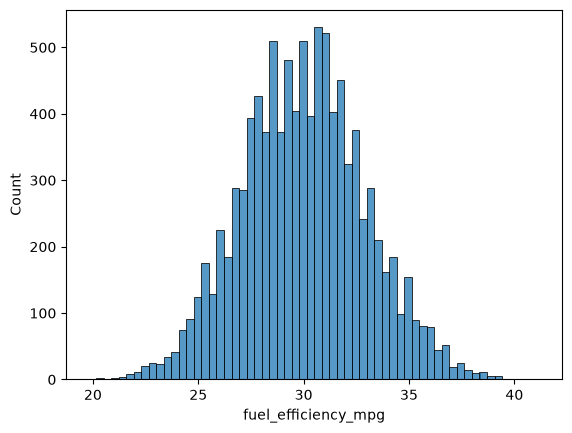

In [8]:
sns.histplot(y)

In [9]:
# Q 1 A: horsepower
X.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

In [10]:
# Q 2 A: 254.0
X['horsepower'].median()

np.float64(254.0)

In [11]:
# Prepare and split the dataset

n = len(X)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = X.iloc[idx[:n_train]]
y_train = y.iloc[idx[:n_train]]

df_val = X.iloc[idx[n_train:n_train + n_val]]
y_val = y.iloc[idx[n_train:n_train + n_val]]

df_test = X.iloc[idx[n_train + n_val:]]
y_test = y.iloc[idx[n_train + n_val:]]

In [12]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    se =  (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [13]:
# Q3 A: Mean (They are so close within 0.003 of each other.)
# fill df with zeroes
def prepare_zeroes(df):
    df = df.copy()
    df = df.fillna(0)

    return df.values

# fill df with mean from training data
train_horsepower_mean = df_train['horsepower'].mean()
def prepare_mean(df):
    df = df.copy()
    df = df.fillna(train_horsepower_mean)

    return df.values

In [14]:
df_train.columns

Index(['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year'], dtype='str')

In [15]:
# prpare and train with zeroes
df_train_zeroes = prepare_zeroes(df_train)
w_0_zeroes, w_zeroes = train_linear_regression(df_train_zeroes, y_train)

df_train_mean = prepare_mean(df_train)
w_0_mean, w_mean = train_linear_regression(df_train_mean, y_train)

w_0_zeroes, w_zeroes, w_0_mean, w_mean

(np.float64(-153.8849618823138),
 array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01]),
 np.float64(-153.29645639114293),
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

In [16]:
# calculate RMSE for both methods

# calculate y_pred_zereos
X_val_zeroes = prepare_zeroes(df_val)
y_pred_zeroes = w_0_zeroes + X_val_zeroes.dot(w_zeroes)

# calculate y_pred_mean
X_val_mean = prepare_mean(df_val)
y_pred_mean = w_0_mean + X_val_mean.dot(w_mean)

rmse_zeroes = round(rmse(y_val, y_pred_zeroes), 3)
rmse_mean = round(rmse(y_val, y_pred_mean), 3)
f'RMSE Zeroes: {rmse_zeroes}', f'RMSE Mean: {rmse_mean}', f'Difference {rmse_zeroes - rmse_mean}'

('RMSE Zeroes: 2.205', 'RMSE Mean: 2.202', 'Difference 0.0030000000000001137')

In [ ]:
# Q4 A: r = 0

def train_linear_regression_reg(X, y, r=0.01):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [20]:
df_train_zeroes = prepare_zeroes(df_train)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    df_train_zeroes = prepare_zeroes(df_train)
    w_0_zeroes_reg, w_zeroes_reg = train_linear_regression_reg(df_train_zeroes, y_train, r=r)

    # calculate predictions
    X_val_zeroes = prepare_zeroes(df_val)
    y_pred_zeroes_reg = w_0_zeroes_reg + X_val_zeroes.dot(w_zeroes_reg)

    rmse_zeroes_reg = round(rmse(y_val, y_pred_zeroes_reg), 4)

    print(f'For r = {r}, RMSE = {rmse_zeroes_reg}')

For r = 0, RMSE = 2.2053
For r = 0.01, RMSE = 2.2058
For r = 0.1, RMSE = 2.2241
For r = 1, RMSE = 2.3492
For r = 5, RMSE = 2.4094
For r = 10, RMSE = 2.4195
For r = 100, RMSE = 2.4292


In [ ]:
# Q5 A: 0.029
seed_values = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

def create_train_test_split(X, seed_value):
    n = len(X)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed_value)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = X.iloc[idx[:n_train]]
    y_train = y.iloc[idx[:n_train]]

    df_val = X.iloc[idx[n_train:n_train + n_val]]
    y_val = y.iloc[idx[n_train:n_train + n_val]]

    df_test = X.iloc[idx[n_train + n_val:]]
    y_test = y.iloc[idx[n_train + n_val:]]

    return df_train, y_train, df_val, y_val, df_test, y_test

rmse_seeds = []
for v in seed_values:
    df_train, y_train, df_val, y_val, df_test, y_test = create_train_test_split(X, v)

    df_train_zeroes = prepare_zeroes(df_train)
    w_0_zeroes, w_zeroes = train_linear_regression(df_train_zeroes, y_train)
    
    # calculate predictions
    X_val_zeroes = prepare_zeroes(df_val)
    y_pred_zeroes = w_0_zeroes + X_val_zeroes.dot(w_zeroes)
    
    rmse_zeroes = rmse(y_val, y_pred_zeroes)
    
    rmse_seeds.append(rmse_zeroes)
    

In [35]:
print(round(np.std(rmse_seeds), 3))

0.029


In [44]:
# Q6 A: 2.235827747191731
df_train, y_train, df_val, y_val, df_test, y_test = create_train_test_split(X, 9)

X_combined = pd.concat([df_train, df_val], axis=0, ignore_index=True)
y_combined = np.concatenate([y_train, y_val])

X_combined_zeroes = prepare_zeroes(X_combined)

w_0_combined, w_combined = train_linear_regression_reg(X_combined_zeroes, y_combined, r=0.001)

# calculate predictions on test data
X_test_zeroes = prepare_zeroes(df_test)
y_pred_test_zeroes = w_0_combined + X_test_zeroes.dot(w_combined)

rmse(y_test, y_pred_test_zeroes)

np.float64(2.235827747191731)